# Dark Ecology Intelligence (DEI) — Phase 4: GloBI Investigation
## Notebook 04: GBIF Taxonomic Overlap and Graph Neural Network Feasibility

### Academic Context
Project: **Dark Ecology Intelligence: Temporal Graph Neural Networks and Deep Reinforcement Learning for AI-Driven Light Pollution Governance**  
Course: **ANN Lab PBL — AI2531A**  
Phase: **Phase 4 — Taxonomic Cross-Referencing and Graph Feasibility**

---

### Objectives of this Notebook
1. Cross-reference GloBI interaction taxa with our 3,901,020 GBIF occurrence dataset (3,964 unique species).
2. Measure exact binomial species matching rates per study landscape.
3. Evaluate ecological network connectivity across our 300 5 km grid cells.
4. Assess graph suitability: node formulation, edge types, network density, and TGNN modeling feasibility.

In [1]:
import sys
import json
import pandas as pd
from pathlib import Path

# Load summary data
with open("../../data/metadata/phase_4_checks/globi_investigation_summary.json", "r") as f:
    summary_data = json.load(f)

overlap_meta = summary_data["taxonomic_overlap_with_gbif"]
print("Loaded taxonomic overlap metadata.")

Loaded taxonomic overlap metadata.


### 1. Overall Taxonomic Overlap
Across our three study regions:
- **Total unique taxa in GloBI**: 1,206 taxa.
- **Total unique species in GBIF DWCA**: 3,964 species.
- **Exact direct binomial matches**: 615 species (51.0% of all GloBI taxa).

In [2]:
print(f"Total Unique GloBI Taxa: {overlap_meta['total_unique_globi_taxa']}")
print(f"Total Unique GBIF Species: {overlap_meta['total_gbif_species']}")
print(f"Exact Binomial Matches: {overlap_meta['total_exact_binomial_matches']} ({overlap_meta['total_overlap_percentage']:.1f}%)")

# Display regional breakdown
overlap_rows = []
for reg_key, info in overlap_meta["regional_breakdown"].items():
    overlap_rows.append({
        "Region": reg_key.title(),
        "Unique GloBI Taxa": info["globi_taxa_count"],
        "GBIF Binomial Matches": info["exact_binomial_overlap_count"],
        "Match Percentage": f"{info['overlap_percentage']:.1f}%",
        "Sample Overlapping Taxa": ", ".join(info["sample_overlapping_species"][:4])
    })

pd.DataFrame(overlap_rows)

Total Unique GloBI Taxa: 1206
Total Unique GBIF Species: 3964
Exact Binomial Matches: 615 (51.0%)


,Region,Unique GloBI Taxa,GBIF Binomial Matches,Match Percentage,Sample Overlapping Taxa
0,Bengaluru,996,514,51.6%,"Abutilon hirtum, Achaea janata, Acherontia lac..."
1,Mysuru,370,228,61.6%,"Abutilon indicum, Acraea terpsicore, Acridothe..."
2,Nilgiri_Bandipur,119,60,50.4%,"Apis dorsata, Apis florea, Argyreia cuneata, A..."


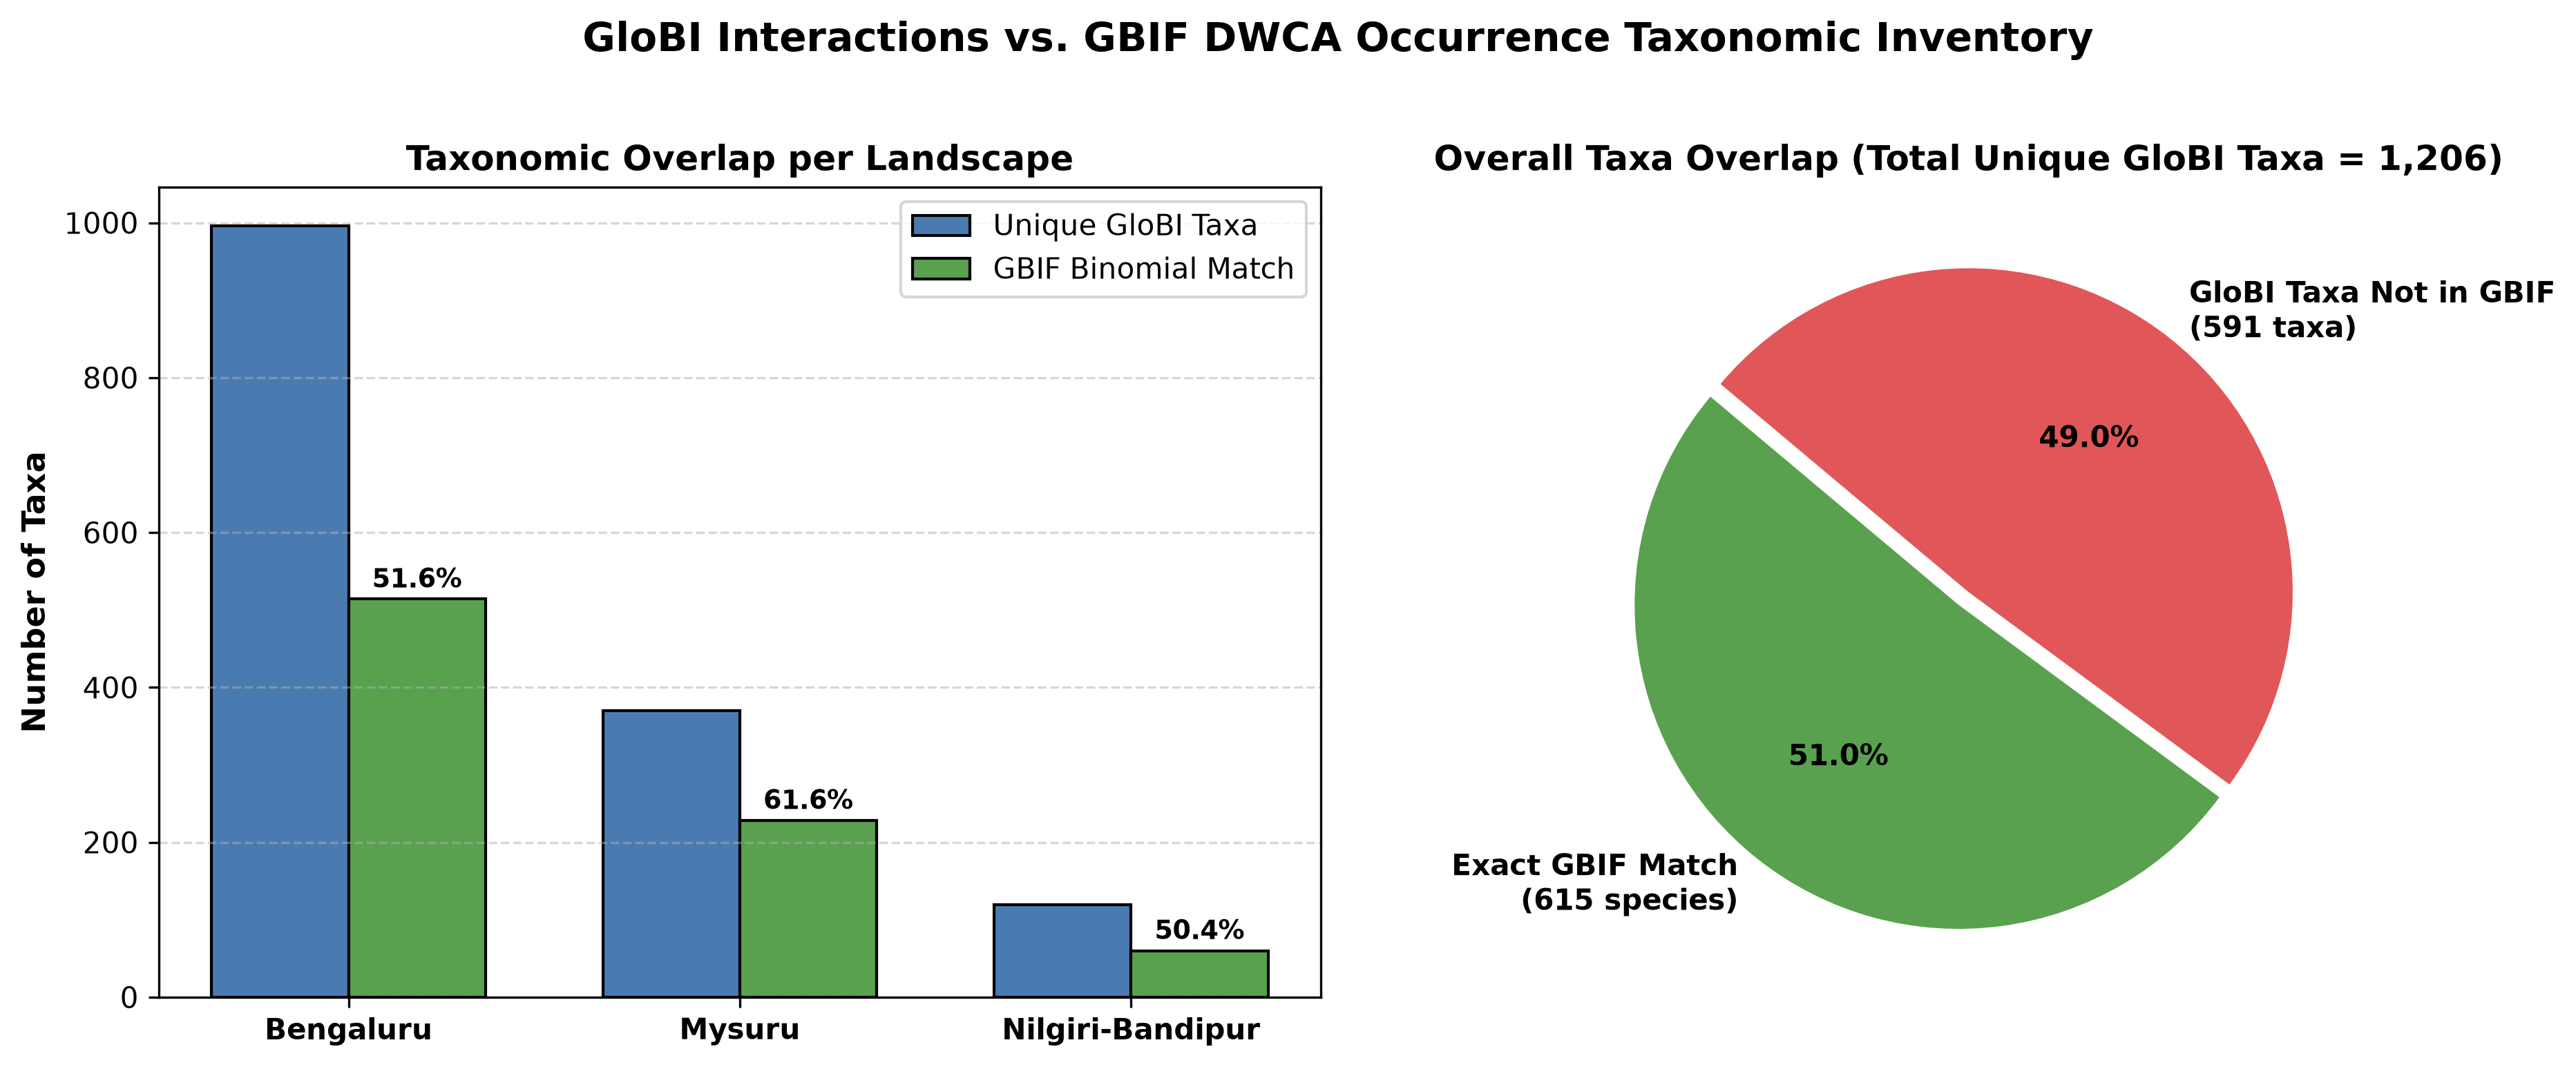

In [3]:
# Display Figure: Taxonomic Overlap
fig_path = Path("../../reports/phase_4/figures/globi_gbif_taxonomic_overlap.png")
if fig_path.exists():
    from IPython.display import Image
    display(Image(filename=str(fig_path)))

### 2. Why Are Some GloBI Taxa Not in GBIF?
1. **Taxonomic Rank Discordance**: Some GloBI taxa are recorded at higher ranks (genus, family, e.g., *Ficus*, *Apis*, *Pompilidae*), whereas GBIF occurrences are indexed at species binomials.
2. **eBird Dominance in GBIF**: As established in Phase 3, 98.06% of GBIF records are birds. GloBI contains extensive plant-insect interactions (butterflies on host plants), many of which are under-represented in eBird.
3. **Taxonomic Synonyms**: Certain scientific names differ between iNaturalist / GloBI taxonomies and GBIF Backbone.

### 3. Graph Suitability and Neural Network Formulation
For our eventual Temporal Graph Neural Network (TGNN):
1. **Node Definition**:
   - Species $v_i \in \mathcal{V}$ present in grid cell $c$ at time $t$ (derived from GBIF occurrences).
2. **Edge Definition**:
   - Directed ecological interaction $(v_i, v_j, r)$ where $r \in \{	ext{preysOn}, 	ext{eats}, 	ext{pollinates}, 	ext{hasHost}\}$ (derived from GloBI).
3. **Static Master Graph vs. Dynamic Realized Subgraph**:
   - GloBI provides the *potential trophic scaffold* (regional interaction network).
   - Realized interactions in cell $c$ at year $t$ exist if both interacting species co-occur in cell $c$ at time $t$.
4. **Feasibility Verdict**: **HIGHLY SUITABLE WITH METHODOLOGICAL CAVEATS**.
   - GloBI empirical interactions directly ground the graph edges in empirical observations rather than synthetic or fabricated connections.